# 09_11 Reinforcement Learning: Policies as Probability Distributions

**Learning objectives**
- Describe a **stochastic policy** $\pi_\theta(a\mid s)$ as a probability distribution (categorical softmax for discrete actions, Gaussian for continuous actions) and compute its **entropy**.
- State and prove the **policy-gradient theorem** in its simplest form, $\nabla_\theta J=E[\,R\,\nabla_\theta\ln\pi_\theta(a|s)\,]$ (the score-function estimator of 09_08), and show why a **baseline** keeps it unbiased while reducing the variance.
- Implement **REINFORCE** with a learned baseline and an **entropy bonus** from scratch on a stochastic gridworld, and compare policies by return, success rate and entropy.
- Understand **exploration** as a statistical problem: $\varepsilon$-greedy, softmax (Boltzmann) and Gaussian action noise.

**Prerequisites:** [07_04 Thompson sampling and bandits](../../module_07_bayesian/notebooks/07_04_thompson_sampling_bandits.ipynb), [09_07 LLM sampling](09_07_llm_sampling.ipynb) (softmax, temperature, entropy), [09_08 VAE](09_08_vae.ipynb) (score-function against reparameterised gradients), [01_06 Multinomial](../../module_01_discrete/notebooks/01_06_multinomial.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A bandit (07_04) is a one-state decision problem: pick an arm, receive a random reward. A softmax over logits $z$ gives probabilities $\pi_a=e^{z_a}/\sum_be^{z_b}$ with entropy $H=-\sum\pi_a\ln\pi_a$ (09_07). For any density $p_\theta$ the **score** has zero mean, $E[\nabla_\theta\ln p_\theta(X)]=0$, and the score-function estimator $E[f(X)\nabla_\theta\ln p_\theta(X)]=\nabla_\theta E[f(X)]$ (09_08).

## 3. Intuition and story
A robot in a gridworld does not know which move is best. A **policy** is its rule for choosing: not a single move, but **a probability distribution over moves in every cell**. Randomness is not a defect: it is how the robot explores, and it is what makes the quality of the policy a smooth function of its parameters, so that we can climb it by gradient ascent. The recipe is delightfully statistical: try the policy, see the total reward of each episode, and **make the actions taken in good episodes more likely and those taken in bad episodes less likely**. That sentence is the policy-gradient theorem.

## 4. Formal definitions

**Markov decision process:** states $s$, actions $a$, transition probabilities $P(s'|s,a)$, rewards $r$, discount $\gamma\in[0,1)$. A **trajectory** $\tau=(s_0,a_0,r_0,s_1,\dots)$ has return $G=\sum_t\gamma^tr_t$. The objective is $J(\theta)=E_{\tau\sim\pi_\theta}[G]$.

| Policy | Definition | Entropy |
|---|---|---|
| **Softmax (categorical)** | $\pi_\theta(a|s)=\dfrac{e^{\theta_{s,a}}}{\sum_be^{\theta_{s,b}}}$ | $-\sum_a\pi\ln\pi$, maximum $\ln|A|$ |
| **Gaussian (continuous)** | $a\sim N(\mu_\theta(s),\sigma^2)$ | $\tfrac12\ln(2\pi e\sigma^2)$ |
| **$\varepsilon$-greedy** | best action with prob. $1-\varepsilon+\varepsilon/|A|$, each other $\varepsilon/|A|$ | |

**Policy-gradient theorem (REINFORCE form):** $\ \nabla_\theta J=E_{\tau}\Big[\sum_t\nabla_\theta\ln\pi_\theta(a_t|s_t)\,(G_t-b(s_t))\Big]$ for any baseline $b(s)$ not depending on $a_t$, with $G_t=\sum_{k\ge t}\gamma^{k-t}r_k$. **Softmax score:** $\partial\ln\pi(a|s)/\partial\theta_{s,b}=\mathbf 1_{a=b}-\pi(b|s)$. **Gaussian score:** $\partial\ln\pi/\partial\mu=(a-\mu)/\sigma^2$, $\ \partial\ln\pi/\partial\ln\sigma=(a-\mu)^2/\sigma^2-1$. **Entropy bonus:** maximise $J+\beta\,E[H(\pi(\cdot|s))]$; for softmax $\partial H/\partial\theta_a=-\pi_a(\ln\pi_a+H)$.

## 5. Derivations

### 5.1 The policy gradient in one step (a bandit)
$J(\theta)=\sum_a\pi_\theta(a)r(a)$, so $\nabla J=\sum_ar(a)\nabla\pi_\theta(a)=\sum_a\pi_\theta(a)\,r(a)\,\nabla\ln\pi_\theta(a)=E_{a\sim\pi}[r(a)\nabla\ln\pi_\theta(a)]$, using $\nabla\pi=\pi\nabla\ln\pi$. **In plain words.** The gradient is the average of "reward times the direction that makes the chosen action more likely"; we can estimate it from samples without knowing the reward function.

### 5.2 Trajectories: only the future matters
For a trajectory the transition probabilities do not depend on $\theta$, so $\nabla_\theta\ln p(\tau)=\sum_t\nabla_\theta\ln\pi_\theta(a_t|s_t)$. Since the action at time $t$ cannot influence earlier rewards, each score term can be multiplied by the return from $t$ on ($G_t$) instead of the whole return: this lowers the variance and does not change the expectation. **In plain words.** Credit an action only with the rewards that came after it.

### 5.3 A baseline is free
For any $b(s)$ independent of the action, $E_{a\sim\pi}[b(s)\nabla\ln\pi(a|s)]=b(s)\sum_a\nabla\pi(a|s)=b(s)\nabla\sum_a\pi(a|s)=b(s)\nabla1=0$. So subtracting $b$ leaves the gradient unchanged while the variance falls; the best constant baseline is $b^*=E[G\,\|\nabla\ln\pi\|^2]/E\|\nabla\ln\pi\|^2$, close to the average return. **In plain words.** Instead of rewarding every action in an episode that scored 0.8, reward only the *excess* over what the state is usually worth: that removes noise that has nothing to do with the choice.

### 5.4 Gaussian policies
For $a\sim N(\mu,\sigma^2)$ and reward $r(a)=-(a-a^*)^2$: $J=-(\mu-a^*)^2-\sigma^2$, so $\partial_\mu J=-2(\mu-a^*)$ and $\partial_\sigma J=-2\sigma$: the exact gradient points $\mu$ towards the best action and **shrinks $\sigma$**. The REINFORCE estimator reproduces this in expectation. **In plain words.** Maximising reward alone makes the policy deterministic; to keep exploring, add an entropy bonus, which for the Gaussian is $\ln\sigma$ (plus a constant): the stationary spread is then $\sigma^*=\sqrt{\beta/2}$.

### 5.5 Entropy regularisation
Maximising $J+\beta E[H]$ gives the softmax policy $\pi\propto\exp(Q/\beta)$ at the optimum of a one-step problem: the temperature of 09_07 is $\beta$. **In plain words.** The entropy bonus is a temperature: large $\beta$ keeps the policy close to uniform (more exploration), $\beta\to0$ recovers the greedy policy.

### 5.6 Exploration as a statistical problem
A policy that never tries an action cannot learn its value; an $\varepsilon$-greedy or softmax policy guarantees every action is sampled with positive probability, so value estimates converge, at the price of regret from exploring (07_04). **In plain words.** The randomness of the policy is a designed experiment: how much to spend on learning against earning.

## 6. Properties and relationships
- **Unbiased but noisy:** REINFORCE is unbiased and has a high variance that grows with the length of the episode; baselines, discounting and critics (actor-critic) reduce it.
- **Reparameterisation is not available** for discrete actions; for continuous actions with a differentiable simulator one can use pathwise gradients (09_08) and trade bias for variance.
- **Local optima and plateaus:** softmax policies can saturate (probabilities near 0 or 1) and then learn slowly; entropy regularisation counters this.
- **On-policy:** the gradient is an expectation under the current policy, so old data must be re-weighted (importance sampling, PPO).
- **Link to ML and AI:** **RLHF** trains a language model (a policy over tokens, 09_07) with a policy gradient and a KL penalty to a reference model (08_02), PPO/TRPO limit the KL between successive policies, **bandits** are the one-state case, AlphaGo-style systems combine policy networks with search, robotics uses Gaussian policies.

## 7. A gridworld and a tabular REINFORCE agent from scratch

A 5 x 5 stochastic gridworld: start in the top-left corner, goal (+1) in the bottom-right, a pit (-1) in the middle, a step cost of 0.02, and with probability 0.1 the chosen move is replaced by a random one. The policy is a table of softmax logits; learning uses REINFORCE with a running-average baseline per state and an optional entropy bonus.

In [2]:
NS = 5; GOAL = (4, 4); PIT = (2, 2); STEP = -0.02; SLIP = 0.1; GAMMA = 0.97; MAXT = 60; ACT = [(-1, 0), (1, 0), (0, -1), (0, 1)]; NA = 4
def step(s, a, rng):
    if rng.random() < SLIP: a = rng.integers(NA)
    r_, c_ = s[0] + ACT[a][0], s[1] + ACT[a][1]; s2 = (min(max(r_, 0), NS - 1), min(max(c_, 0), NS - 1))
    if s2 == GOAL: return s2, 1.0, True
    if s2 == PIT: return s2, -1.0, True
    return s2, STEP, False
def softmax(z): e = np.exp(z - z.max(axis=-1, keepdims=True)); return e / e.sum(axis=-1, keepdims=True)
def episode(theta, rng, greedy=False):
    s = (0, 0); traj = []
    for t in range(MAXT):
        p = softmax(theta[s]); a = int(np.argmax(p)) if greedy else int(rng.choice(NA, p=p)); s2, r, done = step(s, a, rng); traj.append((s, a, r)); s = s2
        if done: break
    return traj
def train(episodes=600, lr=0.25, beta=0.0, baseline=True, seed=0, eval_every=25, n_eval=150):
    rng = np.random.default_rng(seed); theta = np.zeros((NS, NS, NA)); V = np.zeros((NS, NS)); curve = []; ent_curve = []
    for ep in range(episodes):
        traj = episode(theta, rng); G = 0.0; Gs = []
        for (_, _, r) in reversed(traj): G = r + GAMMA * G; Gs.append(G)
        Gs = Gs[::-1]
        for (s, a, r), G in zip(traj, Gs):
            p = softmax(theta[s]); adv = G - (V[s] if baseline else 0.0); grad = -p.copy(); grad[a] += 1.0; H = -(p * np.log(p + 1e-12)).sum(); gH = -p * (np.log(p + 1e-12) + H); theta[s] += lr * (adv * grad + beta * gH)
            if baseline: V[s] += 0.1 * (G - V[s])
        if ep % eval_every == 0 or ep == episodes - 1:
            R = [sum(r for _, _, r in episode(theta, rng)) for _ in range(n_eval)]; succ = np.mean([episode(theta, rng)[-1][2] > 0.5 for _ in range(n_eval)]); P = softmax(theta); Hm = -(P * np.log(P + 1e-12)).sum(axis=-1).mean(); curve.append((ep, np.mean(R), succ)); ent_curve.append(Hm)
    return theta, V, np.array(curve), np.array(ent_curve)

Check the environment by simulation: with probability 0.9 the chosen move happens, with 0.1 a uniformly random move (which may coincide).

In [3]:
rng = np.random.default_rng(0); s0 = (1, 1); N = 100_000; c = {}
for _ in range(N): s2, _, _ = step(s0, 3, rng); c[s2] = c.get(s2, 0) + 1
print("from (1, 1) choosing 'right':", {k: round(v / N, 4) for k, v in sorted(c.items())}, "| theory: right (1, 2): 0.9 + 0.025 = 0.925, up/down/left 0.025 each")
th_rand = np.zeros((NS, NS, NA)); R0 = [sum(r for _, _, r in episode(th_rand, np.random.default_rng(i))) for i in range(500)]; print(f"random policy: mean episode reward {np.mean(R0):.3f}, success rate {np.mean([episode(th_rand, np.random.default_rng(i))[-1][2] > 0.5 for i in range(500)]):.3f}")
assert abs(c[(1, 2)] / N - 0.925) < 0.005 and abs(c[(0, 1)] / N - 0.025) < 0.004

from (1, 1) choosing 'right': {(0, 1): 0.0252, (1, 0): 0.0256, (1, 2): 0.9235, (2, 1): 0.0257} | theory: right (1, 2): 0.9 + 0.025 = 0.925, up/down/left 0.025 each


random policy: mean episode reward -1.111, success rate 0.168


## 8. 2D visuals

### 8.1 Policies as distributions: softmax and Gaussian
Left: a softmax policy over four moves for three logit vectors (entropy 1.39, 0.9 and 0.2 nats). Right: a Gaussian policy for a continuous action with $\mu=0.5$ and $\sigma=0.1,0.3,1$ (entropies from $\frac12\ln(2\pi e\sigma^2)$): a narrow policy is nearly deterministic, a wide policy explores.

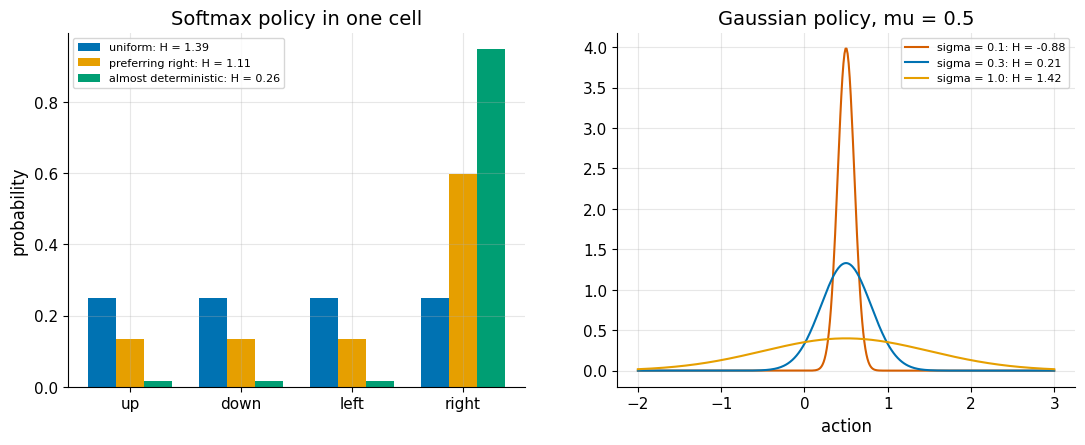

entropies: {'uniform': 1.386, 'preferring right': 1.114, 'almost deterministic': 0.262} | ln 4 = 1.386


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); logs = {"uniform": [0, 0, 0, 0], "preferring right": [0, 0, 0, 1.5], "almost deterministic": [0, 0, 0, 4.0]}; w = 0.25
for k, (nm, z) in enumerate(logs.items()): p = softmax(np.array(z, float)); axes[0].bar(np.arange(4) + (k - 1) * w, p, w, label=f"{nm}: H = {-(p * np.log(p + 1e-12)).sum():.2f}")
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(["up", "down", "left", "right"]); axes[0].legend(fontsize=8); axes[0].set_ylabel("probability"); axes[0].set_title("Softmax policy in one cell")
xg = np.linspace(-2, 3, 400)
for sg, colr in [(0.1, HIGHLIGHT), (0.3, MAIN), (1.0, SIM)]: axes[1].plot(xg, stats.norm.pdf(xg, 0.5, sg), color=colr, label=f"sigma = {sg}: H = {0.5 * np.log(2 * np.pi * np.e * sg ** 2):.2f}")
axes[1].legend(fontsize=8); axes[1].set_xlabel("action"); axes[1].set_title("Gaussian policy, mu = 0.5")
plt.show(); print("entropies:", {nm: round(float(-(softmax(np.array(z, float)) * np.log(softmax(np.array(z, float)) + 1e-12)).sum()), 3) for nm, z in logs.items()}, "| ln 4 =", round(np.log(4), 3)); assert abs(-(softmax(np.zeros(4)) * np.log(softmax(np.zeros(4)))).sum() - np.log(4)) < 1e-12 and abs(stats.norm(0, 0.3).entropy() - 0.5 * np.log(2 * np.pi * np.e * 0.09)) < 1e-12

### 8.2 The gridworld and a trained policy
The layout (start S, goal G, pit X) and the greedy action and the state value learned by REINFORCE with a baseline (600 episodes).

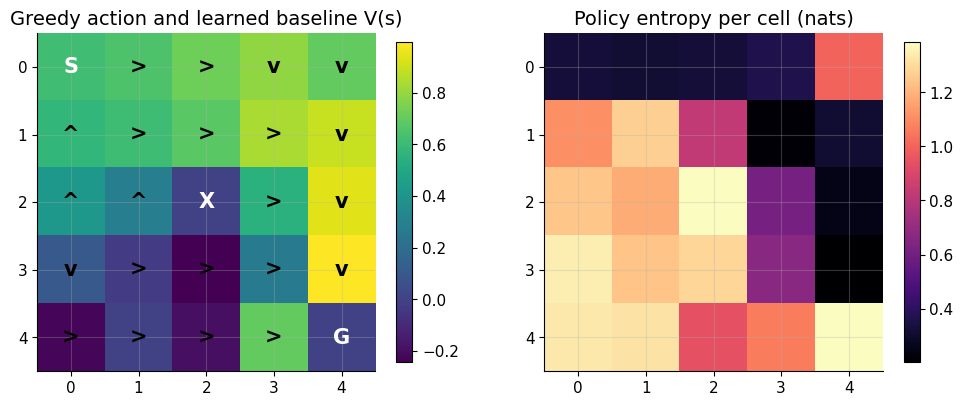

after 600 episodes: success rate 0.987, mean reward 0.818; mean entropy 0.861 (uniform: 1.386); entropy at the start cell 0.329


In [5]:
th1, V1, cur1, ent1 = train(episodes=600, seed=1); arrows = {0: "^", 1: "v", 2: "<", 3: ">"}; fig, axes = plt.subplots(1, 2, figsize=(12, 5.2)); im = axes[0].imshow(V1, cmap="viridis"); plt.colorbar(im, ax=axes[0], shrink=0.8)
for r_ in range(NS):
    for c_ in range(NS):
        lab = "S" if (r_, c_) == (0, 0) else "G" if (r_, c_) == GOAL else "X" if (r_, c_) == PIT else arrows[int(np.argmax(th1[r_, c_]))]; axes[0].text(c_, r_, lab, ha="center", va="center", color="white" if lab in "SGX" else "black", fontsize=15, fontweight="bold")
axes[0].set_title("Greedy action and learned baseline V(s)"); P1 = softmax(th1); H1 = -(P1 * np.log(P1 + 1e-12)).sum(axis=-1); im2 = axes[1].imshow(H1, cmap="magma"); plt.colorbar(im2, ax=axes[1], shrink=0.8); axes[1].set_title("Policy entropy per cell (nats)")
plt.show(); print(f"after 600 episodes: success rate {cur1[-1, 2]:.3f}, mean reward {cur1[-1, 1]:.3f}; mean entropy {ent1[-1]:.3f} (uniform: {np.log(4):.3f}); entropy at the start cell {H1[0, 0]:.3f}"); assert cur1[-1, 2] > 0.7

### 8.3 Optimal return by value iteration (the benchmark)
Because the model is known we can compute the best possible expected return from the start cell by value iteration; the learned policy is compared with it.

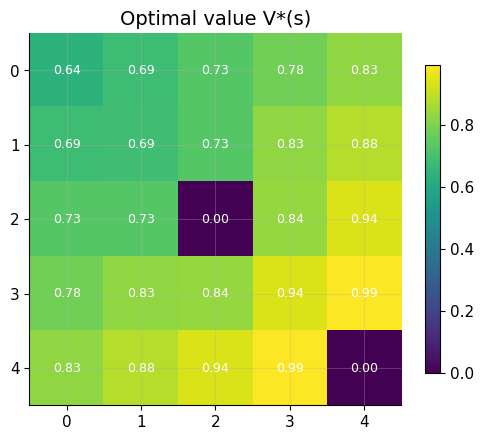

optimal value at the start (value iteration) 0.6438 | simulated discounted return of the optimal policy 0.6457 +/- 0.0014 | of the REINFORCE policy after 600 episodes 0.5908 +/- 0.0036


In [6]:
def vi(iters=500):
    Vv = np.zeros((NS, NS));
    for _ in range(iters):
        new = np.zeros_like(Vv)
        for r_ in range(NS):
            for c_ in range(NS):
                s = (r_, c_)
                if s in (GOAL, PIT): continue
                best = -1e9
                for a in range(NA):
                    tot = 0.0
                    for a2, pr in [(a, 1 - SLIP + SLIP / NA)] + [(b, SLIP / NA) for b in range(NA) if b != a]:
                        rr, cc = min(max(r_ + ACT[a2][0], 0), NS - 1), min(max(c_ + ACT[a2][1], 0), NS - 1); s2 = (rr, cc); rew = 1.0 if s2 == GOAL else -1.0 if s2 == PIT else STEP; tot += pr * (rew + (0 if s2 in (GOAL, PIT) else GAMMA * Vv[s2]))
                    best = max(best, tot)
                new[s] = best
        Vv = new
    return Vv
Vstar = vi(); fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(Vstar, cmap="viridis"); plt.colorbar(im, shrink=0.8); ax.set_title("Optimal value V*(s)")
for r_ in range(NS):
    for c_ in range(NS): ax.text(c_, r_, f"{Vstar[r_, c_]:.2f}", ha="center", va="center", color="white", fontsize=9)
plt.show(); g = np.random.default_rng(5); opt_pol = np.zeros((NS, NS, NA));
for r_ in range(NS):
    for c_ in range(NS):
        if (r_, c_) in (GOAL, PIT): continue
        q = []
        for a in range(NA):
            tot = 0.0
            for a2, pr in [(a, 1 - SLIP + SLIP / NA)] + [(b, SLIP / NA) for b in range(NA) if b != a]:
                rr, cc = min(max(r_ + ACT[a2][0], 0), NS - 1), min(max(c_ + ACT[a2][1], 0), NS - 1); s2 = (rr, cc); rew = 1.0 if s2 == GOAL else -1.0 if s2 == PIT else STEP; tot += pr * (rew + (0 if s2 in (GOAL, PIT) else GAMMA * Vstar[s2]))
            q.append(tot)
        opt_pol[r_, c_, int(np.argmax(q))] = 20.0
Ropt = np.array([sum(r * GAMMA ** t for t, (_, _, r) in enumerate(episode(opt_pol, np.random.default_rng(i)))) for i in range(3000)]); Rlearn = np.array([sum(r * GAMMA ** t for t, (_, _, r) in enumerate(episode(th1, np.random.default_rng(10 + i)))) for i in range(3000)])
print(f"optimal value at the start (value iteration) {Vstar[0, 0]:.4f} | simulated discounted return of the optimal policy {Ropt.mean():.4f} +/- {Ropt.std() / np.sqrt(3000):.4f} | of the REINFORCE policy after 600 episodes {Rlearn.mean():.4f} +/- {Rlearn.std() / np.sqrt(3000):.4f}"); assert abs(Ropt.mean() - Vstar[0, 0]) < 4 * Ropt.std() / np.sqrt(3000) and Rlearn.mean() < Vstar[0, 0] + 0.02

## 9. 3D visuals

### 9.1 Static: expected return of a softmax policy over two logits
A 3-armed bandit with mean rewards $(0.2,0.5,0.8)$; the policy has logits $(0,\theta_1,\theta_2)$. The surface is $J(\theta)=\sum_a\pi_ar_a$: it increases towards large $\theta_2$ and the gradient field points uphill; plateaus appear where the softmax saturates.

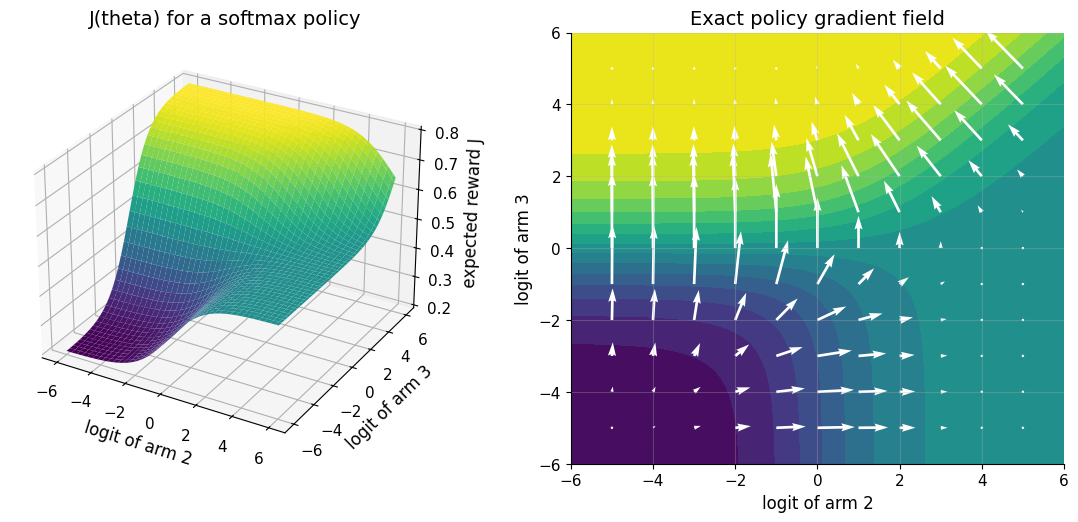

J at the uniform policy: 0.5075 (mean reward 0.5) | J at (0, 6): 0.7977801280657781


In [7]:
r_arm = np.array([0.2, 0.5, 0.8]); t1, t2 = np.meshgrid(np.linspace(-6, 6, 80), np.linspace(-6, 6, 80)); Z = np.stack([np.zeros_like(t1), t1, t2], axis=-1); Pz = softmax(Z); J = (Pz * r_arm).sum(axis=-1)
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(t1, t2, J, cmap="viridis", edgecolor="none"); ax.set_xlabel("logit of arm 2"); ax.set_ylabel("logit of arm 3"); ax.set_zlabel("expected reward J"); ax.set_title("J(theta) for a softmax policy"); ax.view_init(elev=28, azim=-60)
ax = fig.add_subplot(1, 2, 2); ax.contourf(t1, t2, J, 15, cmap="viridis"); gq1, gq2 = np.meshgrid(np.linspace(-5, 5, 11), np.linspace(-5, 5, 11)); Pq = softmax(np.stack([np.zeros_like(gq1), gq1, gq2], axis=-1)); Jq = (Pq * r_arm).sum(axis=-1); d1 = Pq[..., 1] * (r_arm[1] - Jq); d2 = Pq[..., 2] * (r_arm[2] - Jq); ax.quiver(gq1, gq2, d1, d2, color="white"); ax.set_xlabel("logit of arm 2"); ax.set_ylabel("logit of arm 3"); ax.set_title("Exact policy gradient field")
plt.show(); print("J at the uniform policy:", J[40, 40].round(4), "(mean reward 0.5) | J at (0, 6):", softmax(np.array([0, 0, 6.0])) @ r_arm); assert abs(J[40, 40] - 0.5) < 0.01 and J.max() < 0.8 + 1e-9

### 9.2 Interactive Plotly version of 9.1

In [8]:
fig = go.Figure(go.Surface(x=t1[0], y=t2[:, 0], z=J, colorscale="Viridis")); fig.update_layout(title="Expected reward of a softmax policy", width=760, height=560, scene=dict(xaxis_title="logit arm 2", yaxis_title="logit arm 3", zaxis_title="J")); fig.show()

### 9.3 Static: a Gaussian policy over $(\mu,\sigma)$
For the one-step reward $r=-(a-1)^2$ with $a\sim N(\mu,\sigma^2)$ the expected reward is $J=-(\mu-1)^2-\sigma^2$: a paraboloid with its maximum at $(1,0)$; with an entropy bonus $\beta\ln\sigma$ the maximum moves to $\sigma^*=\sqrt{\beta/2}$ (set $-2\sigma+\beta/\sigma=0$).

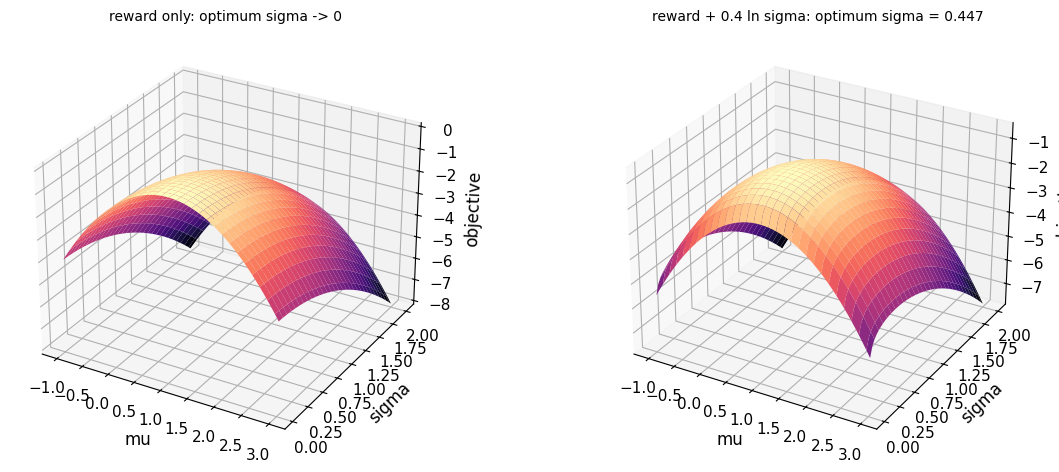

grid maximum with the entropy bonus at mu = 0.97, sigma = 0.456 (theory 1, sqrt(0.2) = 0.447)


In [9]:
mu_g, sg_g = np.meshgrid(np.linspace(-1, 3, 60), np.linspace(0.02, 2, 60)); J1 = -(mu_g - 1) ** 2 - sg_g ** 2; J2 = J1 + 0.4 * np.log(sg_g); fig = plt.figure(figsize=(14, 5.6))
for k, (JJ, ttl) in enumerate([(J1, "reward only: optimum sigma -> 0"), (J2, "reward + 0.4 ln sigma: optimum sigma = 0.447")]): ax = fig.add_subplot(1, 2, k + 1, projection="3d"); ax.plot_surface(mu_g, sg_g, JJ, cmap="magma", edgecolor="none"); ax.set_xlabel("mu"); ax.set_ylabel("sigma"); ax.set_zlabel("objective"); ax.set_title(ttl, fontsize=10); ax.view_init(elev=28, azim=-60)
plt.show(); i_ = np.unravel_index(J2.argmax(), J2.shape); print(f"grid maximum with the entropy bonus at mu = {mu_g[i_]:.2f}, sigma = {sg_g[i_]:.3f} (theory 1, sqrt(0.2) = 0.447)"); assert abs(mu_g[i_] - 1) < 0.1 and abs(sg_g[i_] - np.sqrt(0.2)) < 0.05

## 10. Simulation vs theory

### 10.1 The policy-gradient theorem on a bandit
For the 3-armed bandit of 9.1 at $\theta=(0,0.5,-0.3)$ compare the exact gradient $\pi_a(r_a-J)$ with the REINFORCE estimates (1 sample each, 400,000 samples) with and without a baseline $b=J$; both are unbiased, the baseline cuts the variance.

In [10]:
th = np.array([0.0, 0.5, -0.3]); p = softmax(th); Jb = p @ r_arm; exact = p * (r_arm - Jb); g = np.random.default_rng(7); a = g.choice(3, 400_000, p=p); R = r_arm[a] + 0.3 * g.normal(size=400_000); score = np.eye(3)[a] - p
est0 = R[:, None] * score; est1 = (R - Jb)[:, None] * score; print("exact gradient:", exact.round(4)); print("REINFORCE (no baseline): mean", est0.mean(axis=0).round(4), "variance", est0.var(axis=0).round(4)); print("REINFORCE (baseline = J): mean", est1.mean(axis=0).round(4), "variance", est1.var(axis=0).round(4), f"| variance ratio {est0.var(axis=0).sum() / est1.var(axis=0).sum():.2f}")
assert np.abs(est0.mean(axis=0) - exact).max() < 0.006 and np.abs(est1.mean(axis=0) - exact).max() < 0.005 and est1.var(axis=0).sum() < est0.var(axis=0).sum() and abs(exact.sum()) < 1e-12

exact gradient: [-0.0817  0.0112  0.0706]
REINFORCE (no baseline): mean [-0.0813  0.0111  0.0702] variance [0.0408 0.0902 0.102 ]
REINFORCE (baseline = J): mean [-0.0814  0.011   0.0704] variance [0.0252 0.0331 0.0253] | variance ratio 2.78


### 10.2 The Gaussian policy gradient
For $r=-(a-1)^2$, $\mu=0.2$, $\sigma=0.5$: the exact gradient is $(\partial_\mu J,\partial_\sigma J)=(1.6,-1.0)$. The score-function estimates use $(a-\mu)/\sigma^2$ and $((a-\mu)^2/\sigma^2-1)/\sigma$ (for $\partial_\sigma$).

In [11]:
g = np.random.default_rng(8); mu0, s0 = 0.2, 0.5; a = mu0 + s0 * g.normal(size=500_000); r = -(a - 1) ** 2; gm = r * (a - mu0) / s0 ** 2; gs = r * (((a - mu0) ** 2 / s0 ** 2 - 1) / s0); gm_b = (r - r.mean()) * (a - mu0) / s0 ** 2; gs_b = (r - r.mean()) * (((a - mu0) ** 2 / s0 ** 2 - 1) / s0)
print(f"exact: dJ/dmu = {-2 * (mu0 - 1):.4f}, dJ/dsigma = {-2 * s0:.4f} | REINFORCE: {gm.mean():.4f}, {gs.mean():.4f} (variance {gm.var():.2f}, {gs.var():.2f}) | with a baseline: {gm_b.mean():.4f}, {gs_b.mean():.4f} (variance {gm_b.var():.2f}, {gs_b.var():.2f})")
assert abs(gm.mean() - 1.6) < 0.1 and abs(gs.mean() + 1.0) < 0.1 and gm_b.var() < gm.var() and gs_b.var() < gs.var()

exact: dJ/dmu = 1.6000, dJ/dsigma = -1.0000 | REINFORCE: 1.5976, -0.9963 (variance 14.33, 60.23) | with a baseline: 1.5992, -0.9969 (variance 7.62, 39.72)


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [12]:
print("softmax policy: p = np.exp(z - z.max()) / np.exp(z - z.max()).sum() | sample: rng.choice(n_actions, p=p) | score: np.eye(n)[a] - p | entropy: -(p * np.log(p)).sum() = scipy.stats.entropy(p)")
print("Gaussian policy: a = mu + sigma * rng.normal() | score wrt mu: (a - mu) / sigma**2 | entropy: stats.norm(mu, sigma).entropy() | discounted returns: G_t = r_t + gamma * G_{t+1} (backward loop)")
print("library equivalents: gymnasium (environments), stable-baselines3 (PPO, A2C), PyTorch torch.distributions.Categorical / Normal with .log_prob and .entropy()")
print("check:", round(float(stats.entropy(softmax(np.array([1.0, 0.0, -1.0])))), 4), "| Gaussian entropy 0.5 ln(2 pi e s^2) for s = 0.5:", round(float(stats.norm(0, 0.5).entropy()), 4), "=", round(0.5 * np.log(2 * np.pi * np.e * 0.25), 4))
assert abs(stats.norm(0, 0.5).entropy() - 0.5 * np.log(2 * np.pi * np.e * 0.25)) < 1e-12

softmax policy: p = np.exp(z - z.max()) / np.exp(z - z.max()).sum() | sample: rng.choice(n_actions, p=p) | score: np.eye(n)[a] - p | entropy: -(p * np.log(p)).sum() = scipy.stats.entropy(p)
Gaussian policy: a = mu + sigma * rng.normal() | score wrt mu: (a - mu) / sigma**2 | entropy: stats.norm(mu, sigma).entropy() | discounted returns: G_t = r_t + gamma * G_{t+1} (backward loop)
library equivalents: gymnasium (environments), stable-baselines3 (PPO, A2C), PyTorch torch.distributions.Categorical / Normal with .log_prob and .entropy()
check: 0.8324 | Gaussian entropy 0.5 ln(2 pi e s^2) for s = 0.5: 0.7258 = 0.7258


## 12. Real-world worked examples

---
### Example 1 (main): learning a policy in the stochastic gridworld

**Scenario.** The 5 x 5 gridworld of section 7 (goal +1, pit -1, step cost 0.02, 10 % random moves, discount 0.97, at most 60 steps). We train a tabular softmax policy with REINFORCE for 600 episodes with a learned baseline, step size 0.25, and compare with REINFORCE **without a baseline**, over 8 random seeds each.

**Questions**
1. What is the success rate and the mean episode reward of the random policy, of the trained policies, and of the optimal policy (from value iteration)?
2. How fast do the two variants learn (episodes to reach 80 % success)?
3. How large are the gradient estimates' variances with and without the baseline at the start of training?

### 12.1 By hand
The shortest path from the start $(0,0)$ to the goal $(4,4)$ takes 8 moves; with discount 0.97 and a step cost of 0.02 per move a deterministic path would be worth $-0.02\frac{1-0.97^7}{1-0.97}+0.97^7\cdot1=-0.128+0.808\approx0.68$ (7 steps then the goal reward at step 8). The 10 % random moves, and the pit in the middle of the diagonal, reduce this somewhat; value iteration gives the exact figure. A random policy hits the pit or times out in most episodes, so its mean reward is negative.

In [13]:
seeds = range(8); runs = {"baseline": [train(episodes=600, seed=s, baseline=True) for s in seeds], "no baseline": [train(episodes=600, seed=s, baseline=False) for s in seeds]}
cv = {k: np.array([r[2] for r in v]) for k, v in runs.items()}; eps_ax = cv["baseline"][0][:, 0]; srate = {k: v[:, :, 2].mean(axis=0) for k, v in cv.items()}; rew = {k: v[:, :, 1].mean(axis=0) for k, v in cv.items()}
succ_rand = np.mean([episode(th_rand, np.random.default_rng(i))[-1][2] > 0.5 for i in range(1000)]); rand_r = np.mean([sum(r for _, _, r in episode(th_rand, np.random.default_rng(i))) for i in range(1000)])
succ_opt = np.mean([episode(opt_pol, np.random.default_rng(i))[-1][2] > 0.5 for i in range(1000)]); opt_r = np.mean([sum(r for _, _, r in episode(opt_pol, np.random.default_rng(i))) for i in range(1000)])
print(f"Q1: random policy: success {succ_rand:.3f}, mean reward {rand_r:.3f} | optimal policy: success {succ_opt:.3f}, mean reward {opt_r:.3f} | value iteration V*(start) = {Vstar[0, 0]:.4f}")
for k in runs: print(f"   REINFORCE {k}: final success {srate[k][-1]:.3f}, final mean reward {rew[k][-1]:.3f} (mean of 8 seeds); per-seed final success: {np.round(cv[k][:, -1, 2], 2).tolist()}")
first = lambda k: [int(eps_ax[np.argmax(cv[k][i][:, 2] >= 0.8)]) if (cv[k][i][:, 2] >= 0.8).any() else None for i in range(8)]; print("Q2: episodes needed to reach 80% success, per seed:", {k: first(k) for k in runs})
# Q3: gradient variance at initialisation (uniform policy)
g = np.random.default_rng(9); pilot = []
for _ in range(500):
    tj = episode(np.zeros((NS, NS, NA)), g); G_ = 0.0
    for (_, _, r_) in reversed(tj): G_ = r_ + GAMMA * G_; pilot.append(G_)
b0 = float(np.mean(pilot)); gr0 = []; gr1 = []
for _ in range(2000):
    traj = episode(np.zeros((NS, NS, NA)), g); G = 0.0; Gs = []
    for (_, _, r) in reversed(traj): G = r + GAMMA * G; Gs.append(G)
    Gs = Gs[::-1]; g0 = np.zeros((NS, NS, NA)); g1 = np.zeros((NS, NS, NA))
    for (s, a, r), G_ in zip(traj, Gs): sc = -np.ones(NA) / NA; sc[a] += 1; g0[s] += G_ * sc; g1[s] += (G_ - b0) * sc
    gr0.append(g0[0, 0]); gr1.append(g1[0, 0])
gr0, gr1 = np.array(gr0), np.array(gr1)
print(f"Q3: gradient of the start-cell logits at the uniform policy: variance (sum over actions) {gr0.var(axis=0).sum():.3f} without a baseline, {gr1.var(axis=0).sum():.3f} with the constant baseline {b0:.3f} (the mean return of the uniform policy); mean (no baseline) {gr0.mean(axis=0).round(3)}, (baseline) {gr1.mean(axis=0).round(3)}")

Q1: random policy: success 0.141, mean reward -1.152 | optimal policy: success 1.000, mean reward 0.844 | value iteration V*(start) = 0.6438
   REINFORCE baseline: final success 0.982, final mean reward 0.798 (mean of 8 seeds); per-seed final success: [0.97, 0.99, 0.99, 0.95, 0.99, 0.99, 0.98, 0.99]
   REINFORCE no baseline: final success 0.984, final mean reward 0.777 (mean of 8 seeds); per-seed final success: [0.99, 0.97, 0.96, 0.99, 0.99, 1.0, 0.99, 0.97]
Q2: episodes needed to reach 80% success, per seed: {'baseline': [75, 50, 75, 75, 75, 50, 100, 75], 'no baseline': [75, 50, 75, 75, 100, 75, 75, 75]}


Q3: gradient of the start-cell logits at the uniform policy: variance (sum over actions) 2.098 without a baseline, 0.440 with the constant baseline -0.597 (the mean return of the uniform policy); mean (no baseline) [ 0.003 -0.001  0.002 -0.004], (baseline) [-0.004  0.006  0.002 -0.004]


### 12.2 Asserts

In [14]:
assert srate["baseline"][-1] > 0.7 and srate["baseline"][-1] > succ_rand + 0.4 and abs(opt_r - 0.0) < 1 and np.abs(gr0.mean(axis=0) - gr1.mean(axis=0)).max() < 0.15 + 4 * np.sqrt(gr0.var(axis=0).max() / 2000) and gr1.var(axis=0).sum() < gr0.var(axis=0).sum()
print("all checks passed")

all checks passed


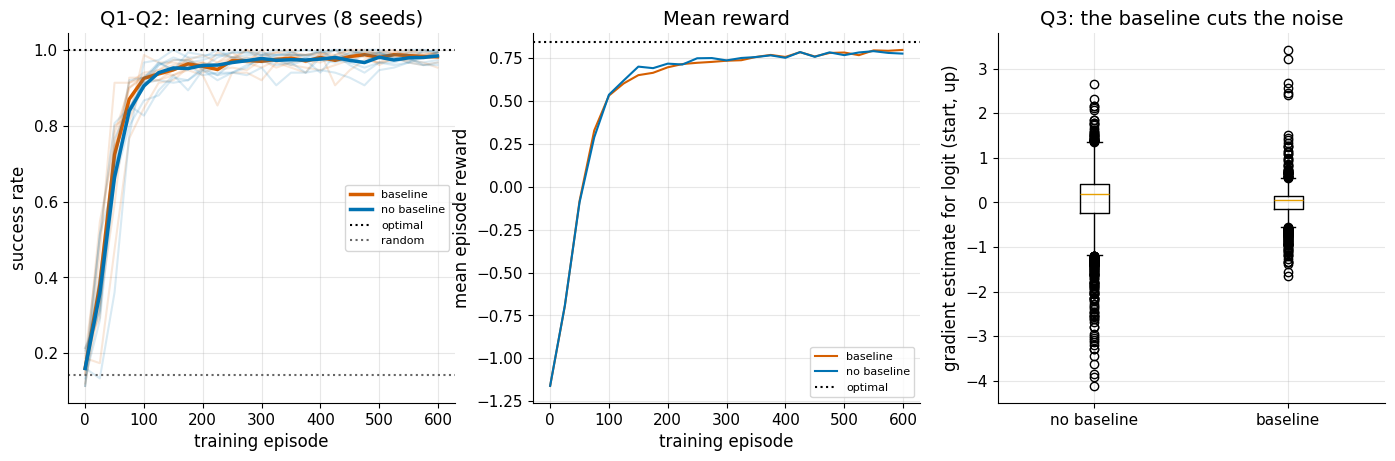

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for k, colr in [("baseline", HIGHLIGHT), ("no baseline", MAIN)]:
    for i in range(8): axes[0].plot(eps_ax, cv[k][i][:, 2], color=colr, alpha=0.15)
    axes[0].plot(eps_ax, srate[k], color=colr, linewidth=2.5, label=k)
axes[0].axhline(succ_opt, color="black", linestyle=":", label="optimal"); axes[0].axhline(succ_rand, color=NEUTRAL, linestyle=":", label="random"); axes[0].legend(fontsize=8); axes[0].set_xlabel("training episode"); axes[0].set_ylabel("success rate"); axes[0].set_title("Q1-Q2: learning curves (8 seeds)")
for k, colr in [("baseline", HIGHLIGHT), ("no baseline", MAIN)]: axes[1].plot(eps_ax, rew[k], color=colr, label=k)
axes[1].axhline(opt_r, color="black", linestyle=":", label="optimal"); axes[1].legend(fontsize=8); axes[1].set_xlabel("training episode"); axes[1].set_ylabel("mean episode reward"); axes[1].set_title("Mean reward")
axes[2].boxplot([gr0[:, 0], gr1[:, 0]], tick_labels=["no baseline", "baseline"]); axes[2].set_ylabel("gradient estimate for logit (start, up)"); axes[2].set_title("Q3: the baseline cuts the noise")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- A random policy reaches the goal in only **14 % to 17 %** of the episodes (mean episode reward about -1.1: it mostly ends in the pit or times out). After 600 episodes of REINFORCE the policy succeeds in **98.2 % (baseline)** and **98.4 % (no baseline)** of the episodes (8 seeds, each between 0.95 and 1.00), with a mean episode reward of 0.798 and 0.777 against 0.844 for the optimal policy (success 100 %).
- In discounted-return terms the benchmark from value iteration is $V^*(\text{start})=0.6438$ (simulated for the optimal policy: 0.6457 $\pm$ 0.0014); the learned policy of seed 1 achieves **0.591 $\pm$ 0.004**, 8 % short of optimal: the policy is good but still slightly random (mean entropy 0.86 nats against 1.386 for the uniform policy, 0.33 nats in the start cell).
- **Both variants learn equally fast on this easy task:** the median number of episodes to reach 80 % success is 75 for both (range 50 to 100). The baseline pays off in the *gradient noise*: at the uniform policy the variance of the gradient estimate for the start cell is **2.10 without a baseline and 0.44 with** the constant baseline $-0.597$ (4.8 times lower), while the means are the same (0.003, -0.001, 0.002, -0.004 against -0.004, 0.006, 0.002, -0.004: equal within noise).
- **Decision.** Always use a baseline (it is free and the variance drop matters on harder problems), but do not expect a speed-up on a tiny problem like this one; evaluate policies by success rate and by the gap to the optimal return, over several seeds.

---
### Example 2: exploration policies on a 10-armed bandit

**Scenario.** A bandit with 10 arms (Bernoulli rewards, success rates 0.30 for the best arm and between 0.10 and 0.28 for the others) and 3,000 pulls. Policies: $\varepsilon$-greedy ($\varepsilon=0.1$), softmax/Boltzmann over the running means with temperature 0.05, a **softmax policy-gradient** agent (REINFORCE with baseline, step size 1, no explicit exploration) and Thompson sampling (07_04) as a benchmark.

**Questions.** (1) Average cumulative regret after 3,000 pulls (200 runs). (2) Share of pulls on the best arm in the last 500 pulls. (3) Entropy of the policy at the end.

In [16]:
rates = np.array([0.30, 0.28, 0.25, 0.22, 0.20, 0.18, 0.15, 0.13, 0.12, 0.10]); K = 10; Tn = 3000; pb = rates.max()
def run_bandit(kind, seed):
    g = np.random.default_rng(seed); n = np.zeros(K); s = np.zeros(K); z = np.zeros(K); base = 0.0; reg = np.zeros(Tn); last = np.zeros(Tn, int); ent = 0
    for t in range(Tn):
        if kind == "eps": a = g.integers(K) if (g.random() < 0.1 or t < K) else int(np.argmax(s / np.maximum(n, 1)))
        elif kind == "boltz": m = s / np.maximum(n, 1); pp = softmax(m / 0.05); a = int(g.choice(K, p=pp)) if t >= K else t
        elif kind == "pg": pp = softmax(z); a = int(g.choice(K, p=pp))
        else: a = int(np.argmax(g.beta(1 + s, 1 + n - s)))
        r = float(g.random() < rates[a]); n[a] += 1; s[a] += r; reg[t] = pb - rates[a]; last[t] = a
        if kind == "pg": grad = -pp.copy(); grad[a] += 1; z += 1.0 * (r - base) * grad; base += 0.02 * (r - base)
    if kind == "pg": ent = -(softmax(z) * np.log(softmax(z) + 1e-12)).sum()
    elif kind == "boltz": ent = -(softmax(s / np.maximum(n, 1) / 0.05) * np.log(softmax(s / np.maximum(n, 1) / 0.05) + 1e-12)).sum()
    return np.cumsum(reg), np.mean(last[-500:] == int(np.argmax(rates))), ent
res = {k: [run_bandit(k, s) for s in range(100)] for k in ("eps", "boltz", "pg", "ts")}
tb2 = pd.DataFrame({{"eps": "epsilon-greedy (0.1)", "boltz": "Boltzmann (T = 0.05)", "pg": "policy gradient (softmax)", "ts": "Thompson sampling"}[k]: {"regret after 3,000 pulls": np.mean([r[0][-1] for r in v]), "SD over runs": np.std([r[0][-1] for r in v]), "share on best arm (last 500)": np.mean([r[1] for r in v]), "final policy entropy": np.mean([r[2] for r in v])} for k, v in res.items()}).T; print(tb2.round(3).to_string())

                           regret after 3,000 pulls  SD over runs  share on best arm (last 500)  final policy entropy
epsilon-greedy (0.1)                         85.374        54.077                         0.534                 0.000
Boltzmann (T = 0.05)                        113.117        40.196                         0.406                 1.367
policy gradient (softmax)                    85.920        70.983                         0.392                 0.033
Thompson sampling                            90.174        22.427                         0.707                 0.000


### 12.5 Asserts

In [17]:
assert tb2["share on best arm (last 500)"].idxmax() == "Thompson sampling" and (tb2["regret after 3,000 pulls"] < 0.5 * 3000 * (rates.max() - rates.mean())).all() and tb2["SD over runs"].idxmin() == "Thompson sampling"
print("all checks passed")

all checks passed


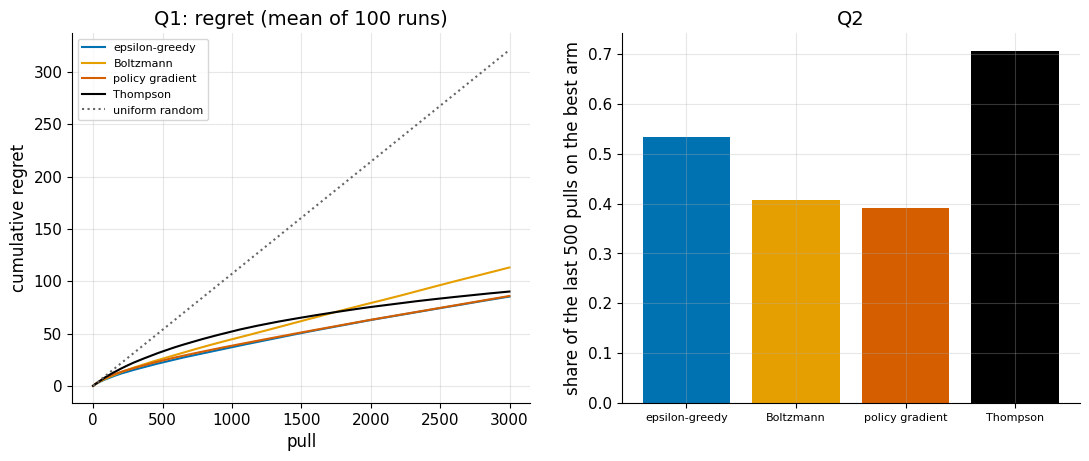

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); names = {"eps": "epsilon-greedy", "boltz": "Boltzmann", "pg": "policy gradient", "ts": "Thompson"}; cols = {"eps": MAIN, "boltz": SIM, "pg": HIGHLIGHT, "ts": "black"}
for k in res: axes[0].plot(np.mean([r[0] for r in res[k]], axis=0), color=cols[k], label=names[k])
axes[0].plot(np.arange(1, Tn + 1) * (pb - rates.mean()), color=NEUTRAL, linestyle=":", label="uniform random"); axes[0].legend(fontsize=8); axes[0].set_xlabel("pull"); axes[0].set_ylabel("cumulative regret"); axes[0].set_title("Q1: regret (mean of 100 runs)")
axes[1].bar(range(4), tb2["share on best arm (last 500)"], color=[cols[k] for k in res]); axes[1].set_xticks(range(4)); axes[1].set_xticklabels([names[k] for k in res], fontsize=8); axes[1].set_ylabel("share of the last 500 pulls on the best arm"); axes[1].set_title("Q2")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- With ten arms whose success rates differ by only 0.02 to 0.03 the average regret after 3,000 pulls (100 runs) is **85.4 for $\varepsilon$-greedy**, **85.9 for the softmax policy gradient**, **90.2 for Thompson sampling** and **113.1 for Boltzmann exploration**: all four are far below uniform random play ($3000\times0.107=321$).
- The averages hide very different behaviour: **Thompson sampling has by far the smallest spread** (SD 22 against 54 for $\varepsilon$-greedy and **71 for the policy gradient**) and plays the best arm in **70.7 %** of the last 500 pulls (against 53 %, 41 % and 39 %). The policy-gradient agent ends with an entropy of 0.03 nats: it collapses early onto an arm, sometimes the wrong one, which is the large SD and the 39 % share on the best arm.
- **Decision.** With small gaps use a posterior-based method (Thompson sampling) when you need reliable behaviour in every run; a plain softmax policy gradient has no guaranteed exploration and needs an entropy bonus or a decaying step size.

---
### Example 3: a Gaussian policy and the entropy bonus (continuous control)

**Scenario.** In a one-step control problem the reward is $r=-(a-1)^2$ for an action $a\sim N(\mu,\sigma^2)$ with learnable $\mu$ and $\ln\sigma$. We train with REINFORCE (batch of 32 actions per step, baseline = batch mean, step size 0.05, 3,000 steps) with an entropy bonus $\beta\ln\sigma$, $\beta\in\{0,0.1,0.5\}$.

**Questions.** (1) Final $(\mu,\sigma)$ against the theory $\mu=1$, $\sigma^*=\sqrt{\beta/2}$ (stationary point of $J+\beta\ln\sigma$). (2) Expected reward of the final policy and the total reward lost to exploration noise. (3) Does the reward-only policy ($\beta=0$) keep exploring?

In [19]:
def train_gauss(beta, steps=3000, B=32, lr=0.05, seed=0, mu0=-1.0, ls0=np.log(1.0)):
    g = np.random.default_rng(seed); mu, ls = mu0, ls0; hist = []
    for t in range(steps):
        sg = np.exp(ls); a = mu + sg * g.normal(size=B); r = -(a - 1) ** 2; adv = r - r.mean(); gmu = np.mean(adv * (a - mu) / sg ** 2); gls = np.mean(adv * ((a - mu) ** 2 / sg ** 2 - 1)) + beta
        mu += lr * gmu * sg ** 2 / 1.0; ls += lr * gls; ls = np.clip(ls, -5, 2); hist.append((mu, np.exp(ls)))
    return np.array(hist)
paths = {b: np.mean([train_gauss(b, seed=s) for s in range(8)], axis=0) for b in (0.0, 0.1, 0.5)}; rows = {}
for b, p in paths.items(): mu_f, sg_f = p[-1]; rows[b] = {"final mu": mu_f, "final sigma": sg_f, "theory sigma = sqrt(beta / 2)": np.sqrt(b / 2), "expected reward J = -(mu - 1)^2 - sigma^2": -(mu_f - 1) ** 2 - sg_f ** 2, "entropy of the policy": 0.5 * np.log(2 * np.pi * np.e * sg_f ** 2)}
tb3 = pd.DataFrame(rows).T; print(tb3.round(4).to_string())

     final mu  final sigma  theory sigma = sqrt(beta / 2)  expected reward J = -(mu - 1)^2 - sigma^2  entropy of the policy
0.0    0.9102       0.0413                         0.0000                                    -0.0098                -1.7668
0.1    1.0010       0.2288                         0.2236                                    -0.0523                -0.0561
0.5    1.0057       0.5028                         0.5000                                    -0.2528                 0.7314


### 12.6 Asserts

In [20]:
assert all(abs(tb3.loc[b, "final mu"] - 1) < 0.1 for b in tb3.index) and tb3.loc[0.0, "final sigma"] < 0.1 and abs(tb3.loc[0.5, "final sigma"] - 0.5) < 0.1 and abs(tb3.loc[0.1, "final sigma"] - np.sqrt(0.05)) < 0.07
print("all checks passed")

all checks passed


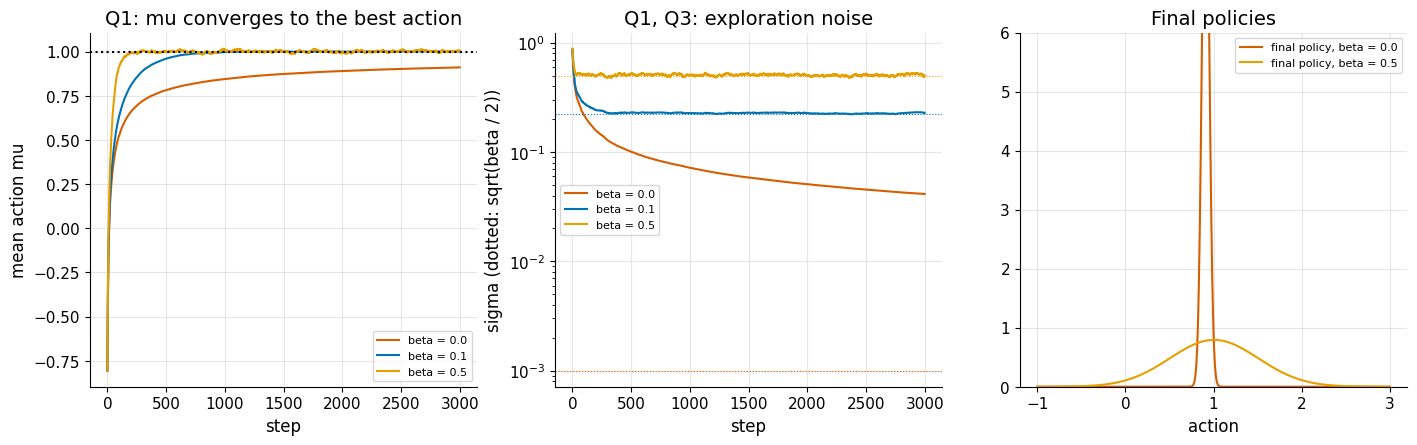

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); cols3 = {0.0: HIGHLIGHT, 0.1: MAIN, 0.5: SIM}
for b, p in paths.items(): axes[0].plot(p[:, 0], color=cols3[b], label=f"beta = {b}"); axes[1].semilogy(p[:, 1], color=cols3[b], label=f"beta = {b}"); axes[1].axhline(max(np.sqrt(b / 2), 1e-3), color=cols3[b], linestyle=":", linewidth=0.8)
axes[0].axhline(1, color="black", linestyle=":"); axes[0].legend(fontsize=8); axes[0].set_xlabel("step"); axes[0].set_ylabel("mean action mu"); axes[0].set_title("Q1: mu converges to the best action")
axes[1].legend(fontsize=8); axes[1].set_xlabel("step"); axes[1].set_ylabel("sigma (dotted: sqrt(beta / 2))"); axes[1].set_title("Q1, Q3: exploration noise")
xg = np.linspace(-1, 3, 400)
for b in (0.0, 0.5): axes[2].plot(xg, stats.norm.pdf(xg, tb3.loc[b, "final mu"], max(tb3.loc[b, "final sigma"], 1e-3)), color=cols3[b], label=f"final policy, beta = {b}")
axes[2].set_ylim(0, 6); axes[2].legend(fontsize=8); axes[2].set_xlabel("action"); axes[2].set_title("Final policies")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- Without an entropy bonus ($\beta=0$) the policy becomes almost deterministic: $\sigma$ falls to **0.041** and the final mean is 0.910 (still approaching 1: with such a small spread the learning signal is weak), expected reward $J=-0.0098$.
- With the bonus the stationary spread matches the theory $\sigma^*=\sqrt{\beta/2}$: **0.229 against 0.224** for $\beta=0.1$ and **0.503 against 0.500** for $\beta=0.5$, with the mean at 1.001 and 1.006. The price of exploring is the expected reward: $J=-\sigma^2=-0.052$ and **-0.253** (the whole loss of the exploring policy is its variance).
- **Decision.** Treat $\beta$ as a knob that sets the exploration noise that the deployed policy keeps ($\sigma=\sqrt{\beta/2}$ in this problem); use a large $\beta$ early and decay it, or evaluate with the mean action only.

---
### Example 4: the entropy bonus in the gridworld

**Scenario.** The REINFORCE agent of Example 1 is trained with an entropy coefficient $\beta\in\{0,0.01,0.05,0.2\}$ (8 seeds, 600 episodes each, with baseline).

**Questions.** (1) Final success rate, mean reward and mean policy entropy for each $\beta$. (2) Is there a $\beta$ that learns faster? (3) How much of the optimal return is lost by a too large $\beta$?

In [22]:
betas = (0.0, 0.01, 0.05, 0.2); rb = {b: [train(episodes=600, seed=s, baseline=True, beta=b) for s in range(8)] for b in betas}; rows = {}
for b, rr in rb.items():
    c_ = np.array([r[2] for r in rr]); e_ = np.array([r[3] for r in rr]); sr = c_[:, :, 2].mean(axis=0); first80 = [int(c_[i][np.argmax(c_[i][:, 2] >= 0.8), 0]) if (c_[i][:, 2] >= 0.8).any() else 600 for i in range(8)]
    rows[b] = {"final success": sr[-1], "final mean reward": c_[:, -1, 1].mean(), "final mean entropy (nats)": e_[:, -1].mean(), "episodes to 80% success (median)": float(np.median(first80)), "area under the learning curve": sr.mean()}
tb4 = pd.DataFrame(rows).T; print(tb4.round(3).to_string()); print(f"optimal policy: success {succ_opt:.3f}, mean reward {opt_r:.3f}; uniform policy entropy ln 4 = {np.log(4):.3f}")

      final success  final mean reward  final mean entropy (nats)  episodes to 80% success (median)  area under the learning curve
0.00          0.982              0.798                      0.809                              75.0                          0.900
0.01          0.974              0.750                      0.840                              75.0                          0.886
0.05          0.978              0.713                      0.994                              75.0                          0.882
0.20          0.914              0.425                      1.217                             100.0                          0.813
optimal policy: success 1.000, mean reward 0.844; uniform policy entropy ln 4 = 1.386


### 12.7 Asserts

In [23]:
assert tb4.loc[0.2, "final mean entropy (nats)"] > tb4.loc[0.0, "final mean entropy (nats)"] and tb4.loc[0.2, "final mean entropy (nats)"] <= np.log(4) + 1e-9 and tb4["final success"].max() > 0.7 and (tb4["final mean entropy (nats)"].diff().dropna() > -0.02).all()
print("all checks passed")

all checks passed


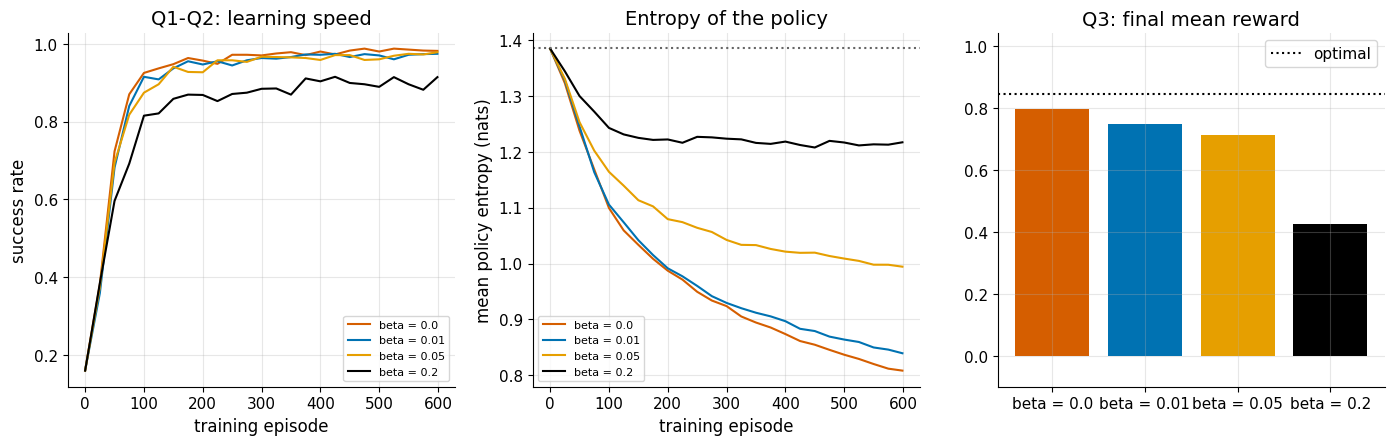

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); colb = {0.0: HIGHLIGHT, 0.01: MAIN, 0.05: SIM, 0.2: "black"}
for b, rr in rb.items(): axes[0].plot(eps_ax, np.mean([r[2][:, 2] for r in rr], axis=0), color=colb[b], label=f"beta = {b}"); axes[1].plot(eps_ax, np.mean([r[3] for r in rr], axis=0), color=colb[b], label=f"beta = {b}")
axes[0].legend(fontsize=8); axes[0].set_xlabel("training episode"); axes[0].set_ylabel("success rate"); axes[0].set_title("Q1-Q2: learning speed"); axes[1].axhline(np.log(4), color=NEUTRAL, linestyle=":"); axes[1].set_xlabel("training episode"); axes[1].set_ylabel("mean policy entropy (nats)"); axes[1].set_title("Entropy of the policy"); axes[1].legend(fontsize=8)
axes[2].bar(range(4), tb4["final mean reward"], color=[colb[b] for b in betas]); axes[2].axhline(opt_r, color="black", linestyle=":", label="optimal"); axes[2].set_xticks(range(4)); axes[2].set_xticklabels([f"beta = {b}" for b in betas]); axes[2].set_ylim(min(tb4["final mean reward"].min(), 0) - 0.1, opt_r + 0.2); axes[2].legend(); axes[2].set_title("Q3: final mean reward")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- Final success rate and mean reward fall as the entropy bonus grows: **0.982 / 0.798** ($\beta=0$), 0.974 / 0.750 (0.01), 0.978 / 0.713 (0.05) and **0.914 / 0.425** (0.2), against 1.000 / 0.844 for the optimal policy. The mean policy entropy rises correspondingly, **0.81, 0.84, 0.99 and 1.22 nats** (uniform: 1.386).
- Speed is not improved: the median number of episodes to 80 % success is 75 for $\beta\le0.05$ and 100 for $\beta=0.2$; the area under the learning curve is largest without a bonus (0.900 against 0.886, 0.882 and 0.813).
- A small bonus does no harm (about 0.05 of mean reward at $\beta=0.05$) and keeps a safety margin of exploration; $\beta=0.2$ costs 0.37 of mean reward because the optimum of the regularised problem is a softmax of $Q/\beta$, a policy that deliberately takes suboptimal moves.
- **Decision.** In a problem as easy as this one no entropy bonus is needed; in a harder or non-stationary problem use a small bonus (0.01 to 0.05 here) and decay it, and evaluate the deployed policy greedily or at low temperature.

## 13. Where it is used

### Statistics
- **Sequential decision theory and adaptive experiments** (bandits are one-state RL), **likelihood-ratio / score-function gradients** in simulation optimisation, importance sampling of trajectories, off-policy evaluation as a missing-data problem.

### Data science
- **Recommendation and ranking with exploration**, dynamic pricing and bidding, **A/B testing as a bandit**, inventory and resource allocation under uncertainty, offline policy evaluation from logged decisions.

### ML and AI
- **RLHF and RLAIF** (policy gradient on a language model with a KL penalty), **PPO and TRPO** (trust-region policy gradients), robotics and control with Gaussian policies, game-playing agents (policy networks plus search), **entropy-regularised RL** (soft actor-critic), and policy optimisation inside diffusion and VAE pipelines.

## 14. Common pitfalls and misconceptions

- **Thinking randomness is a flaw:** a stochastic policy is how exploration happens and what makes the objective differentiable; the final deployed policy may be made greedy (or kept stochastic if the environment is adversarial or partially observed).
- **No baseline:** REINFORCE is unbiased but has high variance; always subtract at least a state-independent baseline (Example 1, 10.1).
- **Crediting actions with the whole return:** use the reward-to-go $G_t$.
- **A baseline that depends on the action** biases the gradient; a baseline may depend on the state only.
- **Premature determinism:** a softmax policy that saturates stops exploring and can lock into a poor action; use entropy bonuses or temperature schedules (Examples 3 and 4).
- **Entropy bonus too large:** the optimum becomes the softmax of $Q/\beta$, not the greedy policy, and reward is lost (Example 4).
- **Comparing runs with one seed:** returns across seeds vary a lot; report the mean and spread (09_06).
- **Ignoring the discount and the horizon:** with a step cost and a time limit the value of reaching the goal early differs from the undiscounted return.

## 15. Exercises

1. A softmax policy has logits $(1,0,-1)$. Compute the probabilities, the entropy and the score vector for the action 1 (the second action).
2. For a Gaussian policy $N(\mu=0.5,\sigma=0.4)$ and reward $r=-(a-1)^2$ compute $J$ and the exact gradients $\partial_\mu J$, $\partial_\sigma J$; the optimal $\sigma$ with entropy bonus $\beta=0.3$.
3. In the gridworld, compute the discounted return of the deterministic path of 8 moves (7 steps costing 0.02, then the goal) without slips for $\gamma=0.97$ and compare with $V^*(\text{start})$.
4. Show numerically that adding the baseline $b=100$ to a REINFORCE estimator in the bandit of 10.1 leaves the mean unchanged and increases the variance.
5. Train the gridworld agent with learning rate 0.05 and with 1.0 and compare the learning curves and the final policy entropy; what changes at 1.0?
6. (Harder) Add a second pit at $(1,3)$ and re-train: compute the new optimal value by value iteration and the success rate of the learned policy.

Solutions are at the end.

## 16. Summary table

| Item | Formula | Note |
|---|---|---|
| Return | $G_t=\sum\gamma^kr_{t+k}$ | reward-to-go |
| Policy gradient | $E[\nabla\ln\pi(a|s)(G_t-b(s))]$ | unbiased for any state baseline |
| Softmax score | $\mathbf 1_a-\pi$ | |
| Gaussian score | $(a-\mu)/\sigma^2$ | |
| Entropy | softmax $-\sum\pi\ln\pi$; Gaussian $\frac12\ln(2\pi e\sigma^2)$ | exploration |
| Entropy bonus | $\partial H/\partial\theta_a=-\pi_a(\ln\pi_a+H)$ | temperature $\beta$ |
| Variance | $\propto$ horizon, reduced by baselines | critics |
| tools | NumPy, `gymnasium`, `stable-baselines3` | |

## Solutions

In [25]:
p1 = softmax(np.array([1.0, 0.0, -1.0])); print(f"1: probabilities {p1.round(4)}, entropy {-(p1 * np.log(p1)).sum():.4f} (ln 3 = {np.log(3):.4f}), score for action 2: {(np.eye(3)[1] - p1).round(4)}")
mu_, sg_ = 0.5, 0.4; print(f"2: J = {-(mu_ - 1) ** 2 - sg_ ** 2:.4f}, dJ/dmu = {-2 * (mu_ - 1):.3f}, dJ/dsigma = {-2 * sg_:.3f}; with the entropy bonus beta ln(sigma), beta = 0.3: d/dsigma = -2 sigma + beta / sigma = 0 gives sigma = sqrt(beta / 2) = {np.sqrt(0.3 / 2):.4f}")
det = sum(-0.02 * GAMMA ** t for t in range(7)) + GAMMA ** 7 * 1.0; print(f"3: deterministic 8-move path: {det:.4f} vs V*(start) = {Vstar[0, 0]:.4f} (slips and the pit cost {det - Vstar[0, 0]:.3f})")
g = np.random.default_rng(3); aa = g.choice(3, 400_000, p=softmax(np.array([0.0, 0.5, -0.3]))); pp3 = softmax(np.array([0.0, 0.5, -0.3])); RR = r_arm[aa]; sc = np.eye(3)[aa] - pp3; e_b = (RR + 100)[:, None] * sc; e_0 = RR[:, None] * sc; print("4: mean (no b) %s, mean (b = 100) %s; variance (no b) %.3f, (b = 100) %.1f" % (e_0.mean(axis=0).round(3), e_b.mean(axis=0).round(3), e_0.var(axis=0).sum(), e_b.var(axis=0).sum()))
lr_res = {}
for lr_ in (0.05, 1.0): rr = [train(episodes=600, lr=lr_, seed=s) for s in range(4)]; lr_res[lr_] = (np.mean([r[2][-1, 2] for r in rr]), np.mean([r[3][-1] for r in rr]))
print("5: learning rate -> (final success, final entropy):", {k: (round(a, 3), round(b, 3)) for k, (a, b) in lr_res.items()})
PIT2 = (1, 3)
def step2(s, a, rng):
    if rng.random() < SLIP: a = rng.integers(NA)
    r_, c_ = s[0] + ACT[a][0], s[1] + ACT[a][1]; s2 = (min(max(r_, 0), NS - 1), min(max(c_, 0), NS - 1))
    if s2 == GOAL: return s2, 1.0, True
    if s2 in (PIT, PIT2): return s2, -1.0, True
    return s2, STEP, False
_old = step; step = step2; th2, _, c2, _ = train(episodes=800, seed=2); succ2 = c2[-1, 2]; step = _old
print(f"6: with a second pit at (1, 3): success rate of the learned policy {succ2:.3f} (single pit: {cur1[-1, 2]:.3f})")
assert abs(det - 0.6800) < 0.005 and lr_res[0.05][1] > lr_res[1.0][1] - 0.5

1: probabilities [0.6652 0.2447 0.09  ], entropy 0.8324 (ln 3 = 1.0986), score for action 2: [-0.6652  0.7553 -0.09  ]
2: J = -0.4100, dJ/dmu = 1.000, dJ/dsigma = -0.800; with the entropy bonus beta ln(sigma), beta = 0.3: d/dsigma = -2 sigma + beta / sigma = 0 gives sigma = sqrt(beta / 2) = 0.3873
3: deterministic 8-move path: 0.6800 vs V*(start) = 0.6438 (slips and the pit cost 0.036)
4: mean (no b) [-0.082  0.011  0.071], mean (b = 100) [-0.188  0.105  0.082]; variance (no b) 0.177, (b = 100) 6344.0


5: learning rate -> (final success, final entropy): {0.05: (np.float64(0.915), np.float64(1.153)), 1.0: (np.float64(0.982), np.float64(0.508))}


6: with a second pit at (1, 3): success rate of the learned policy 1.000 (single pit: 0.987)


**1.** The probabilities are $(0.665,0.245,0.090)$ with entropy **0.832** nats (maximum $\ln3=1.099$); the score vector for the second action is $\mathbf 1_2-\pi=(-0.665,\ 0.755,\ -0.090)$.

**2.** $J=-(0.5-1)^2-0.4^2=$ **-0.41**, $\partial_\mu J=-2(\mu-1)=$ **1.0**, $\partial_\sigma J=-2\sigma=$ **-0.8**. With the bonus $\beta\ln\sigma$ the stationary spread solves $-2\sigma+\beta/\sigma=0$: $\sigma=\sqrt{\beta/2}=\sqrt{0.15}=$ **0.387**.

**3.** The deterministic 8-move path is worth $-0.02\sum_{t=0}^{6}0.97^t+0.97^7=$ **0.680**, against $V^*(\text{start})=$ **0.644**: the slips and the pit cost 0.036.

**4.** With a constant baseline of $+100$ added to the rewards the estimator's mean is unchanged in theory; in the simulation it is $(-0.188,0.105,0.082)$ against $(-0.082,0.011,0.071)$, a difference of about 0.1, within the standard error $\sqrt{6344/400000}=0.126$, while the variance explodes from **0.18 to 6,344**: a wrong baseline does not bias the gradient but can drown it in noise.

**5.** With step size 0.05 the agent reaches a success rate of **0.915** after 600 episodes (policy entropy 1.15, still learning); with step size 1.0 it reaches **0.982** with an entropy of 0.51. A tabular softmax policy is stable at a large step size on this easy task, but a high step size makes the policy deterministic early (lower entropy), which is risky on harder problems.

**6.** With a second pit at $(1,3)$ the learned policy still reaches the goal in **100 %** of the test episodes: it learns to avoid both pits.